# **PHASE 1 - DATA INSPECTION & PREPROCESSING**

In [83]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import os

In [84]:
df = pd.read_csv("data/Week_4_Messy_Housing_Data_2000.csv")

In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Property_ID              2000 non-null   str  
 1   Location                 1976 non-null   str  
 2   Property_Type            1982 non-null   str  
 3   Size_SqFt                1970 non-null   str  
 4   Bedrooms                 1982 non-null   str  
 5   Bathrooms                1977 non-null   str  
 6   Garage_Spaces            1978 non-null   str  
 7   Property_Age_Years       1982 non-null   str  
 8   Distance_City_Center_Km  1975 non-null   str  
 9   Has_Garden               1980 non-null   str  
 10  House_Price              1990 non-null   str  
dtypes: str(11)
memory usage: 172.0 KB


In [86]:
df = df.dropna(subset=['House_Price'])

In [87]:
df['Location'] = df['Location'].astype(str).str.strip().str.title()
df['Property_Type'] = df['Property_Type'].astype(str).str.strip().str.title()

In [88]:
garden_map = {'Yes': 'Yes', 'YES': 'Yes', ' yes ': 'Yes', 'Y': 'Yes',
              'No': 'No', 'NO': 'No', ' no ': 'No', 'N': 'No', 'No ': 'No'}
df['Has_Garden'] = df['Has_Garden'].astype(str).str.strip().map(garden_map)

In [89]:
text_to_num = {'three': '3', 'two': '2', 'five': '5', 'new': '0'}
cols_to_clean = ['Size_SqFt', 'Bedrooms', 'Bathrooms', 'Property_Age_Years']

In [90]:
for col in cols_to_clean:
    df[col] = df[col].astype(str).str.lower()
    for word, digit in text_to_num.items():
        df[col] = df[col].str.replace(word, digit, regex=True)
    # Extract only the numeric characters (ignores 'sqft', 'rooms', 'years')
    df[col] = df[col].str.extract(r'(\d+\.?\d*)').astype(float)

In [91]:
df['House_Price'] = pd.to_numeric(df['House_Price'], errors='coerce')
df['Distance_City_Center_Km'] = pd.to_numeric(df['Distance_City_Center_Km'], errors='coerce')
df['Garage_Spaces'] = pd.to_numeric(df['Garage_Spaces'], errors='coerce')

In [92]:
for col in ['Location', 'Property_Type', 'Has_Garden']:
    df[col] = df[col].replace('Nan', np.nan)
    df[col] = df[col].fillna(df[col].mode()[0])

In [93]:
num_cols = ['Size_SqFt', 'Bedrooms', 'Bathrooms', 'Garage_Spaces', 'Property_Age_Years', 'Distance_City_Center_Km']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [94]:
df = df[df['Size_SqFt'] > 0]
df = df[df['House_Price'] > 0]
df = df[df['Property_Age_Years'] >= 0]

In [95]:
df = df.reset_index(drop=True)

In [96]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1980 entries, 0 to 1979
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Property_ID              1980 non-null   str    
 1   Location                 1980 non-null   str    
 2   Property_Type            1980 non-null   str    
 3   Size_SqFt                1980 non-null   float64
 4   Bedrooms                 1980 non-null   float64
 5   Bathrooms                1980 non-null   float64
 6   Garage_Spaces            1980 non-null   float64
 7   Property_Age_Years       1980 non-null   float64
 8   Distance_City_Center_Km  1980 non-null   float64
 9   Has_Garden               1980 non-null   str    
 10  House_Price              1980 non-null   float64
dtypes: float64(7), str(4)
memory usage: 170.3 KB
None
Property_ID                0
Location                   0
Property_Type              0
Size_SqFt                  0
Bedrooms                   0
Ba

In [97]:
print(df.duplicated().sum())

69


In [102]:
# Final sweep to drop hidden duplicates exposed by text standardization
df = df.drop_duplicates()

# Save the fully cleaned dataset locally
output_filename = 'data/cleaned_housing_data.csv'
df.to_csv(output_filename, index=False)

In [105]:
df = df.reset_index(drop=True)

In [106]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1911 entries, 0 to 1910
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Property_ID              1911 non-null   str    
 1   Location                 1911 non-null   str    
 2   Property_Type            1911 non-null   str    
 3   Size_SqFt                1911 non-null   float64
 4   Bedrooms                 1911 non-null   float64
 5   Bathrooms                1911 non-null   float64
 6   Garage_Spaces            1911 non-null   float64
 7   Property_Age_Years       1911 non-null   float64
 8   Distance_City_Center_Km  1911 non-null   float64
 9   Has_Garden               1911 non-null   str    
 10  House_Price              1911 non-null   float64
dtypes: float64(7), str(4)
memory usage: 164.4 KB


In [107]:
print(f"Final cleaned dataset shape: {df.shape}")

Final cleaned dataset shape: (1911, 11)


In [125]:
output_filename = 'data/cleaned_housing_data.csv'
df.to_csv(output_filename, index=False)
print(f"Data cleaning complete. File saved locally as: {output_filename}")

Data cleaning complete. File saved locally as: data/cleaned_housing_data.csv


# **PHASE 2 - PREPARE THE DATA FOR MACHINE LEARNING**

In [126]:
df = pd.read_csv('data/cleaned_housing_data.csv')

In [110]:
#Remove Property_ID as it is an identifier, not a predictive feature
df = df.drop(columns=['Property_ID'])

In [111]:
X = df.drop(columns=['House_Price'])
y = df['House_Price']

In [112]:
# Convert categorical features into numerical form using One-Hot Encoding
# drop_first=True drops one category per column to avoid multicollinearity (the dummy variable trap)
categorical_cols = ['Location', 'Property_Type', 'Has_Garden']
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

In [113]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

In [114]:
print("=== DATA SHAPES ===")
print(f"Original dataset shape: {df.shape}")
print(f"X_train shape (Features for training): {X_train.shape}")
print(f"y_train shape (Target for training): {y_train.shape}")
print(f"X_test shape (Features for testing): {X_test.shape}")
print(f"y_test shape (Target for testing): {y_test.shape}")

print("\n=== PREPARED FEATURES ===")
print(X_encoded.columns.tolist())

=== DATA SHAPES ===
Original dataset shape: (1911, 10)
X_train shape (Features for training): (1528, 16)
y_train shape (Target for training): (1528,)
X_test shape (Features for testing): (383, 16)
y_test shape (Target for testing): (383,)

=== PREPARED FEATURES ===
['Size_SqFt', 'Bedrooms', 'Bathrooms', 'Garage_Spaces', 'Property_Age_Years', 'Distance_City_Center_Km', 'Location_Asaba', 'Location_Awka', 'Location_Enugu', 'Location_Nnewi', 'Location_Onitsha', 'Property_Type_Bungalow', 'Property_Type_Detached', 'Property_Type_Duplex', 'Property_Type_Terrace', 'Has_Garden_Yes']


# **PHASE 3 - BUILD THE MULTIPLE LINEAR REGRESSION MODEL**

In [115]:
model = LinearRegression()

In [116]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [117]:
y_pred = model.predict(X_test)

In [120]:
comparison_df = pd.DataFrame({'Actual_Price': y_test, 'Predicted_Price': y_pred})
pd.options.display.float_format = '{:,.0f}'.format  # Format with commas for readability
print("=== ACTUAL VS PREDICTED PRICES (SAMPLE) ===")
print(comparison_df.head())

=== ACTUAL VS PREDICTED PRICES (SAMPLE) ===
      Actual_Price  Predicted_Price
1228    29,400,000       24,939,830
111     75,500,000       78,840,738
1844    63,000,000       61,331,942
1335   139,500,000      123,189,906
415     99,100,000      109,063,851


# **PHASE 4 - MODEL EVALUATION**

In [121]:
# Calculate MSE, RMSE, and R-squared
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n=== MODEL EVALUATION METRICS ===")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R-squared (R²): {r2:.4f}")


=== MODEL EVALUATION METRICS ===
Mean Squared Error (MSE): 73,411,538,583,335.86
Root Mean Squared Error (RMSE): 8,568,053.37
R-squared (R²): 0.9184


# **PHASE 5 - MODEL PERFORMANCE VISUALIZATIONS**

In [122]:
# Create the charts directory for the final project structure
os.makedirs('charts', exist_ok=True)

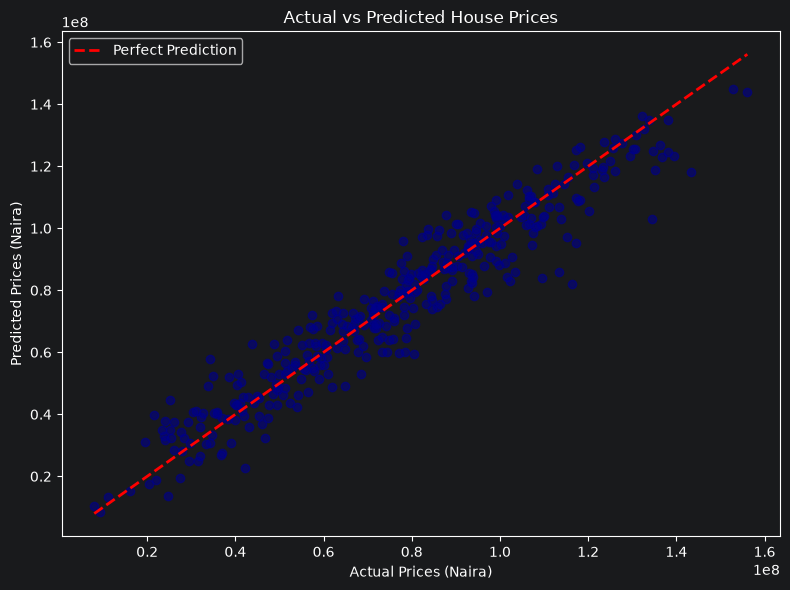

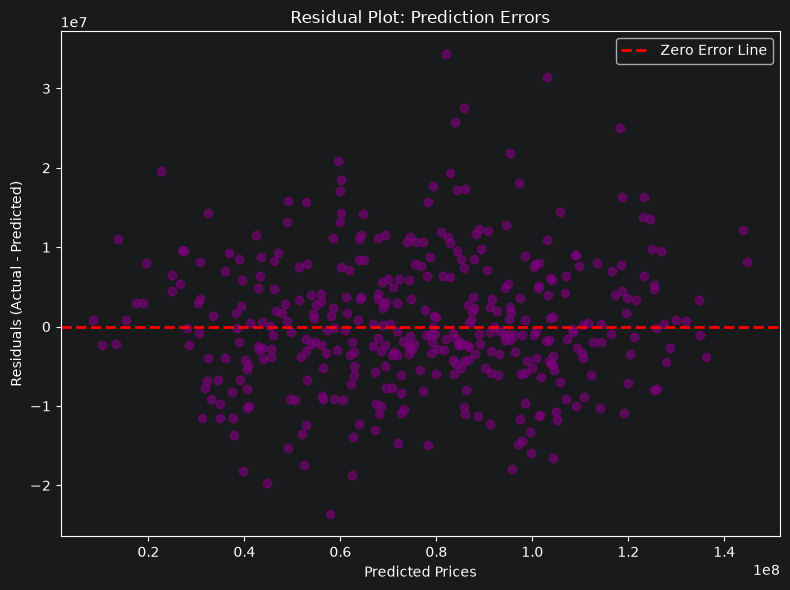

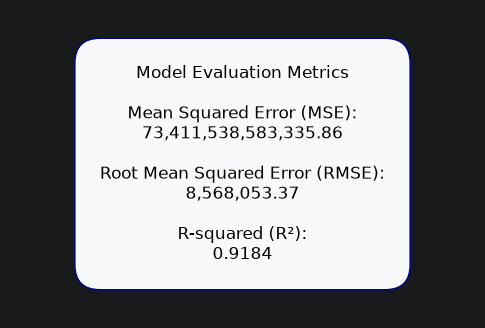

In [123]:
# 18. Actual vs Predicted Prices Plot
plt.figure(figsize=(8, 6))
# Using a dark blue aesthetic for clear visibility
plt.scatter(y_test, y_pred, alpha=0.6, color='darkblue')

# Adding the reference line for perfect predictions
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Prices (Naira)')
plt.ylabel('Predicted Prices (Naira)')
plt.legend()
plt.tight_layout()
plt.savefig('charts/actual_vs_predicted.png')
plt.show()
plt.close()

# 19. Residual/Error Plot
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
# Using a purple aesthetic to distinguish from the first plot
plt.scatter(y_pred, residuals, alpha=0.6, color='purple')
plt.axhline(y=0, color='r', linestyle='--', lw=2, label='Zero Error Line')

plt.title('Residual Plot: Prediction Errors')
plt.xlabel('Predicted Prices')
plt.ylabel('Residuals (Actual - Predicted)')
plt.legend()
plt.tight_layout()
plt.savefig('charts/residual_plot.png')
plt.show()
plt.close()

# 20. Model Evaluation Summary Figure
fig, ax = plt.subplots(figsize=(6, 4))
ax.axis('off')

metrics_text = (
    f"Model Evaluation Metrics\n\n"
    f"Mean Squared Error (MSE):\n{mse:,.2f}\n\n"
    f"Root Mean Squared Error (RMSE):\n{rmse:,.2f}\n\n"
    f"R-squared (R²):\n{r2:.4f}"
)

# Draw a clean box containing the metrics, forcing color='black' for visibility
ax.text(0.5, 0.5, metrics_text, ha='center', va='center', fontsize=12, color='black',
        bbox=dict(boxstyle='round,pad=1.5', facecolor='#f8f9fa', edgecolor='darkblue'))

plt.savefig('charts/model_metrics.png')
plt.show()
plt.close()

# **PHASE 6: PREDICT NEW HOUSE PRICES**

In [124]:
# Create at least three imaginary houses with different combinations of features
new_houses = pd.DataFrame({
    'Size_SqFt': [2500, 1200, 3500],
    'Bedrooms': [4, 2, 5],
    'Bathrooms': [4, 1, 5],
    'Garage_Spaces': [2, 0, 3],
    'Property_Age_Years': [5, 20, 0],
    'Distance_City_Center_Km': [8.5, 15.0, 4.2],
    'Location': ['Awka', 'Aba', 'Enugu'],
    'Property_Type': ['Duplex', 'Bungalow', 'Detached'],
    'Has_Garden': ['Yes', 'No', 'Yes']
})

# 22. Apply the same encoding approach used during training
# First, encode the new categorical data
new_houses_encoded = pd.get_dummies(new_houses, columns=categorical_cols)

# Crucial Step: Align the new data columns with the training data columns (X_encoded)
# This fills in any missing dummy categories with 0s so the model doesn't crash
new_houses_encoded = new_houses_encoded.reindex(columns=X_encoded.columns, fill_value=0)

# 23. Use the trained model to predict the price of each house
new_predictions = model.predict(new_houses_encoded)

# 24. Display the house details together with the predicted price in a readable format
new_houses['Predicted_Price'] = new_predictions

print("\n=== PREDICTIONS FOR NEW HOUSES ===")
print(new_houses.to_string(index=False))


=== PREDICTIONS FOR NEW HOUSES ===
 Size_SqFt  Bedrooms  Bathrooms  Garage_Spaces  Property_Age_Years  Distance_City_Center_Km Location Property_Type Has_Garden  Predicted_Price
      2500         4          4              2                   5                        8     Awka        Duplex        Yes      103,267,201
      1200         2          1              0                  20                       15      Aba      Bungalow         No       27,774,307
      3500         5          5              3                   0                        4    Enugu      Detached        Yes      132,828,949


### Phase 7: Short Model Interpretation

**Which features were used to predict house price?**
The model utilized nine original features to predict house prices: Property Size (SqFt), Bedrooms, Bathrooms, Garage Spaces, Property Age (Years), Distance to City Center (Km), Location, Property Type, and Garden Availability. After One-Hot Encoding the categorical variables, these were expanded into 16 numerical features for the model.

**What preprocessing problems did you discover and how did you handle them?**
The dataset contained several critical data-quality issues:
*   **Mixed Data Types:** Numerical columns (Size, Bedrooms, Age) contained text strings (e.g., "3052 sqft", "three", "new"). I handled this by using regular expressions to strip alphabetical characters, mapping spelled-out words to digits, and forcing the columns to float types.
*   **Inconsistent Categories:** Columns like `Location` and `Property_Type` had varied capitalization and whitespace. I standardized these using string stripping and Title Case. The `Has_Garden` column had multiple variations (Y, yes, N, no), which I mapped to a clean binary "Yes" or "No".
*   **Missing Data & Duplicates:** I dropped 69 total duplicate rows (62 exact copies and 7 hidden duplicates exposed during text standardization). I also dropped 10 rows missing the target `House_Price` and filtered out 10 rows with impossible data (e.g., 0 square feet). I imputed the remaining missing values using the median for numerical columns and the mode for categorical ones.

**What do your MSE, RMSE, and $R^{2}$ results suggest about model performance?**
The model achieved an $R^{2}$ of 0.9184, successfully explaining 91.84% of the variance in house prices. The RMSE of approximately 8.5 million Naira indicates that predictions deviate by an average of 8,568,053 Naira from the actual price. Removing the hidden duplicates directly improved the RMSE by over 500,000 Naira per prediction. While the MSE remains massively inflated (over 73 trillion) due to squaring the errors, the tightened RMSE and strong $R^{2}$ confirm a highly accurate fit without indicating severe overfitting.

**From the actual-vs-predicted and residual plots, where does the model appear to perform well or poorly?**
The actual-vs-predicted scatter plot shows a strong linear grouping along the perfect prediction line, indicating reliable performance across most of the dataset. The residual plot shows a relatively even, random scatter of errors above and below the zero line (homoscedasticity). However, the model appears to struggle slightly more with extreme outliers—particularly underpredicting some of the most expensive properties.

**What limitations does this model or dataset have?**
Multiple Linear Regression assumes a strictly straight-line relationship between the features and the price, which may not capture complex real-world pricing dynamics. Additionally, the dataset is limited to basic structural features and distance metrics; it lacks nuanced variables that heavily influence real estate, such as neighborhood safety, architectural condition, or proximity to specific amenities (schools, markets).

**What could you try in the future to improve the model?**
To improve accuracy, we could engineer new features, such as calculating the "Price per Square Foot." We could also experiment with non-linear Machine Learning models, such as Random Forest or Gradient Boosting (XGBoost), which are better equipped to handle complex feature interactions and outliers than standard Linear Regression.